In [17]:
!pip uninstall mediapipe -y
!pip install mediapipe==0.10.35

'pip' is not recognized as an internal or external command,
operable program or batch file.
'pip' is not recognized as an internal or external command,
operable program or batch file.


In [18]:
!pip install mediapipe opencv-python numpy matplotlib

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [19]:
import mediapipe as mp

print("MediaPipe Version:", mp.__version__)
print("MediaPipe Location:", mp.__file__)

MediaPipe Version: 1.2.3
MediaPipe Location: c:\Users\SKYTOP\miniconda3\envs\gesture_ai\Lib\site-packages\mediapipe\__init__.py


In [20]:
!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("Libraries imported successfully!")

Libraries imported successfully!


In [22]:
base_options = python.BaseOptions(
    model_asset_path="hand_landmarker.task"
)

options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.7,
    min_hand_presence_confidence=0.7,
    min_tracking_confidence=0.7
)

detector = vision.HandLandmarker.create_from_options(options)

print("Hand Landmarker Ready!")

Hand Landmarker Ready!


In [23]:
image = mp.Image.create_from_file("hand.jpg")

result = detector.detect(image)

print("Number of detected hands:", len(result.hand_landmarks))

Number of detected hands: 1


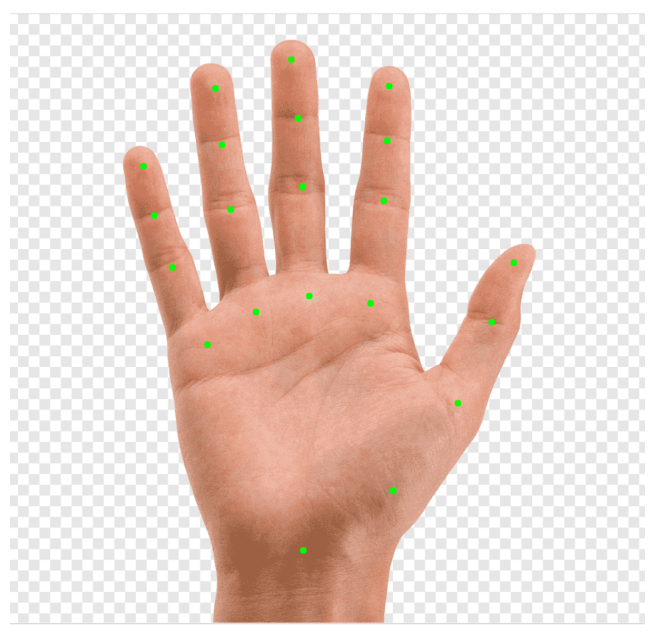

In [24]:
img = cv2.imread("hand.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

height, width, _ = img.shape

for hand_landmarks in result.hand_landmarks:

    for landmark in hand_landmarks:

        x = int(landmark.x * width)
        y = int(landmark.y * height)

        cv2.circle(img, (x, y), 5, (0, 255, 0), -1)

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

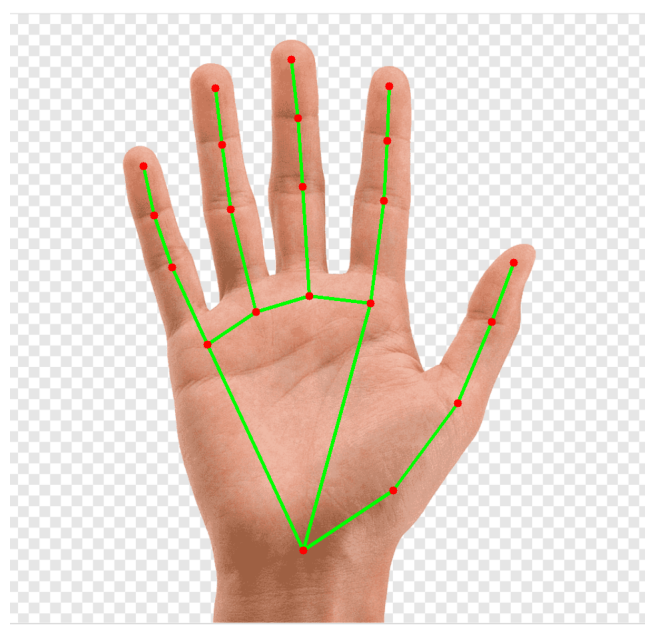

In [25]:
# Copy the original image
output_image = img.copy()

# Hand connections
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17)
]

# Draw landmarks and connections
for hand_landmarks in result.hand_landmarks:

    points = []

    for landmark in hand_landmarks:
        x = int(landmark.x * width)
        y = int(landmark.y * height)
        points.append((x, y))

    # Draw connections
    for start, end in HAND_CONNECTIONS:
        cv2.line(
            output_image,
            points[start],
            points[end],
            (0, 255, 0),
            3
        )

    # Draw landmarks
    for point in points:
        cv2.circle(
            output_image,
            point,
            6,
            (255, 0, 0),
            -1
        )

plt.figure(figsize=(10, 8))
plt.imshow(output_image)
plt.axis("off")
plt.show()

In [26]:
def count_fingers(hand_landmarks):

    finger_tips = [8, 12, 16, 20]
    finger_pips = [6, 10, 14, 18]

    fingers = []

    for tip, pip in zip(finger_tips, finger_pips):

        if hand_landmarks[tip].y < hand_landmarks[pip].y:
            fingers.append(1)

        else:
            fingers.append(0)
    # Thumb
    thumb_open = detect_thumb(hand_landmarks)

    fingers.append(1 if thumb_open else 0)
    return fingers

In [27]:
def recognize_gesture(hand_landmarks):

    fingers = count_fingers(hand_landmarks)

    total_fingers = sum(fingers)

    if total_fingers == 4:
        return "OPEN PALM"

    elif total_fingers == 0:
        return "CLOSED FIST"

    elif total_fingers == 1:
        return "ONE FINGER"

    elif total_fingers == 2:
        return "TWO FINGERS"

    elif total_fingers == 3:
        return "THREE FINGERS"

    return "UNKNOWN"

In [28]:
import math

def calculate_distance(point1, point2):

    return math.sqrt(
        (point1.x - point2.x) ** 2 +
        (point1.y - point2.y) ** 2
    )


def detect_thumb(hand_landmarks):

    thumb_tip = hand_landmarks[4]
    thumb_ip = hand_landmarks[3]
    index_mcp = hand_landmarks[5]

    tip_distance = calculate_distance(
        thumb_tip, index_mcp
    )

    ip_distance = calculate_distance(
        thumb_ip, index_mcp
    )

    return tip_distance > ip_distance * 1.2

In [34]:
import math

def calculate_distance(a, b):
    return math.hypot(a.x - b.x, a.y - b.y)

def count_fingers(lm):
    wrist = lm[0]
    tips = [8, 12, 16, 20]
    pips = [6, 10, 14, 18]
    return [
        1 if calculate_distance(lm[t], wrist) >
             calculate_distance(lm[p], wrist) * 1.1 else 0
        for t, p in zip(tips, pips)
    ]

def detect_thumb(lm):
    palm_width = calculate_distance(lm[5], lm[17])
    away_from_pinky = (calculate_distance(lm[4], lm[17]) >
                       calculate_distance(lm[3], lm[17]) * 1.05)
    away_from_index = calculate_distance(lm[4], lm[5]) > palm_width * 0.7
    return away_from_pinky and away_from_index

def recognize_gesture_v2(lm):
    fingers = count_fingers(lm)
    thumb_open = detect_thumb(lm)
    total = sum(fingers)

    palm_width = calculate_distance(lm[5], lm[17])
    thumb_tip, wrist = lm[4], lm[0]

    # OK sign
    if (calculate_distance(lm[4], lm[8]) < palm_width * 0.25
            and fingers[1] == 1 and fingers[2] == 1 and fingers[3] == 1):
        return "OK SIGN"

    # Thumbs up / down
    if thumb_open and total == 0:
        if thumb_tip.y < wrist.y - palm_width * 0.5:
            return "THUMBS UP"
        if thumb_tip.y > wrist.y + palm_width * 0.5:
            return "THUMBS DOWN"

    # الإبهام مبقاش شرط في الباقي
    if total == 4:
        return "OPEN PALM"
    if total == 0:
        return "CLOSED FIST"
    if total == 1:
        return "ONE FINGER"
    if total == 2:
        return "TWO FINGERS"
    if total == 3:
        return "THREE FINGERS"
    return "UNKNOWN"

In [35]:
for hand_landmarks in result.hand_landmarks:

    gesture = recognize_gesture(hand_landmarks)

    print("Detected Gesture:", gesture)

Detected Gesture: OPEN PALM


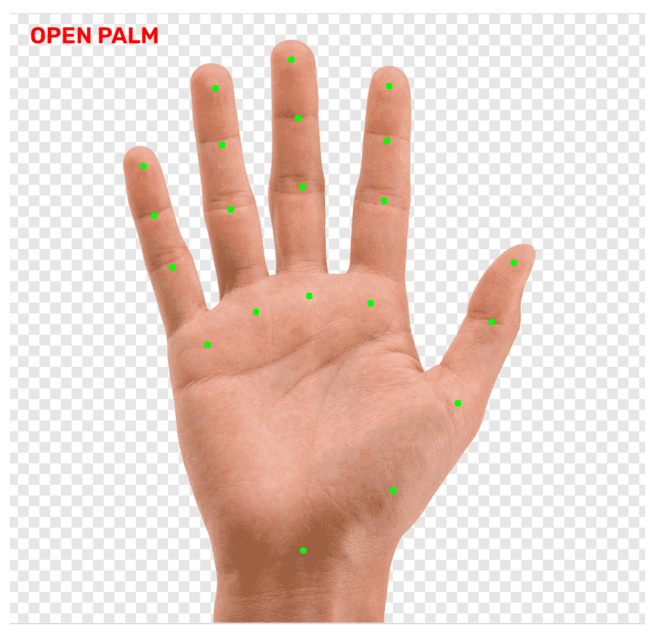

In [36]:
output = img.copy()

for hand_landmarks in result.hand_landmarks:

    gesture = recognize_gesture(hand_landmarks)

    cv2.putText(
        output,
        gesture,
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.2,
        (255, 0, 0),
        3
    )

plt.figure(figsize=(10, 8))
plt.imshow(output)
plt.axis("off")
plt.show()

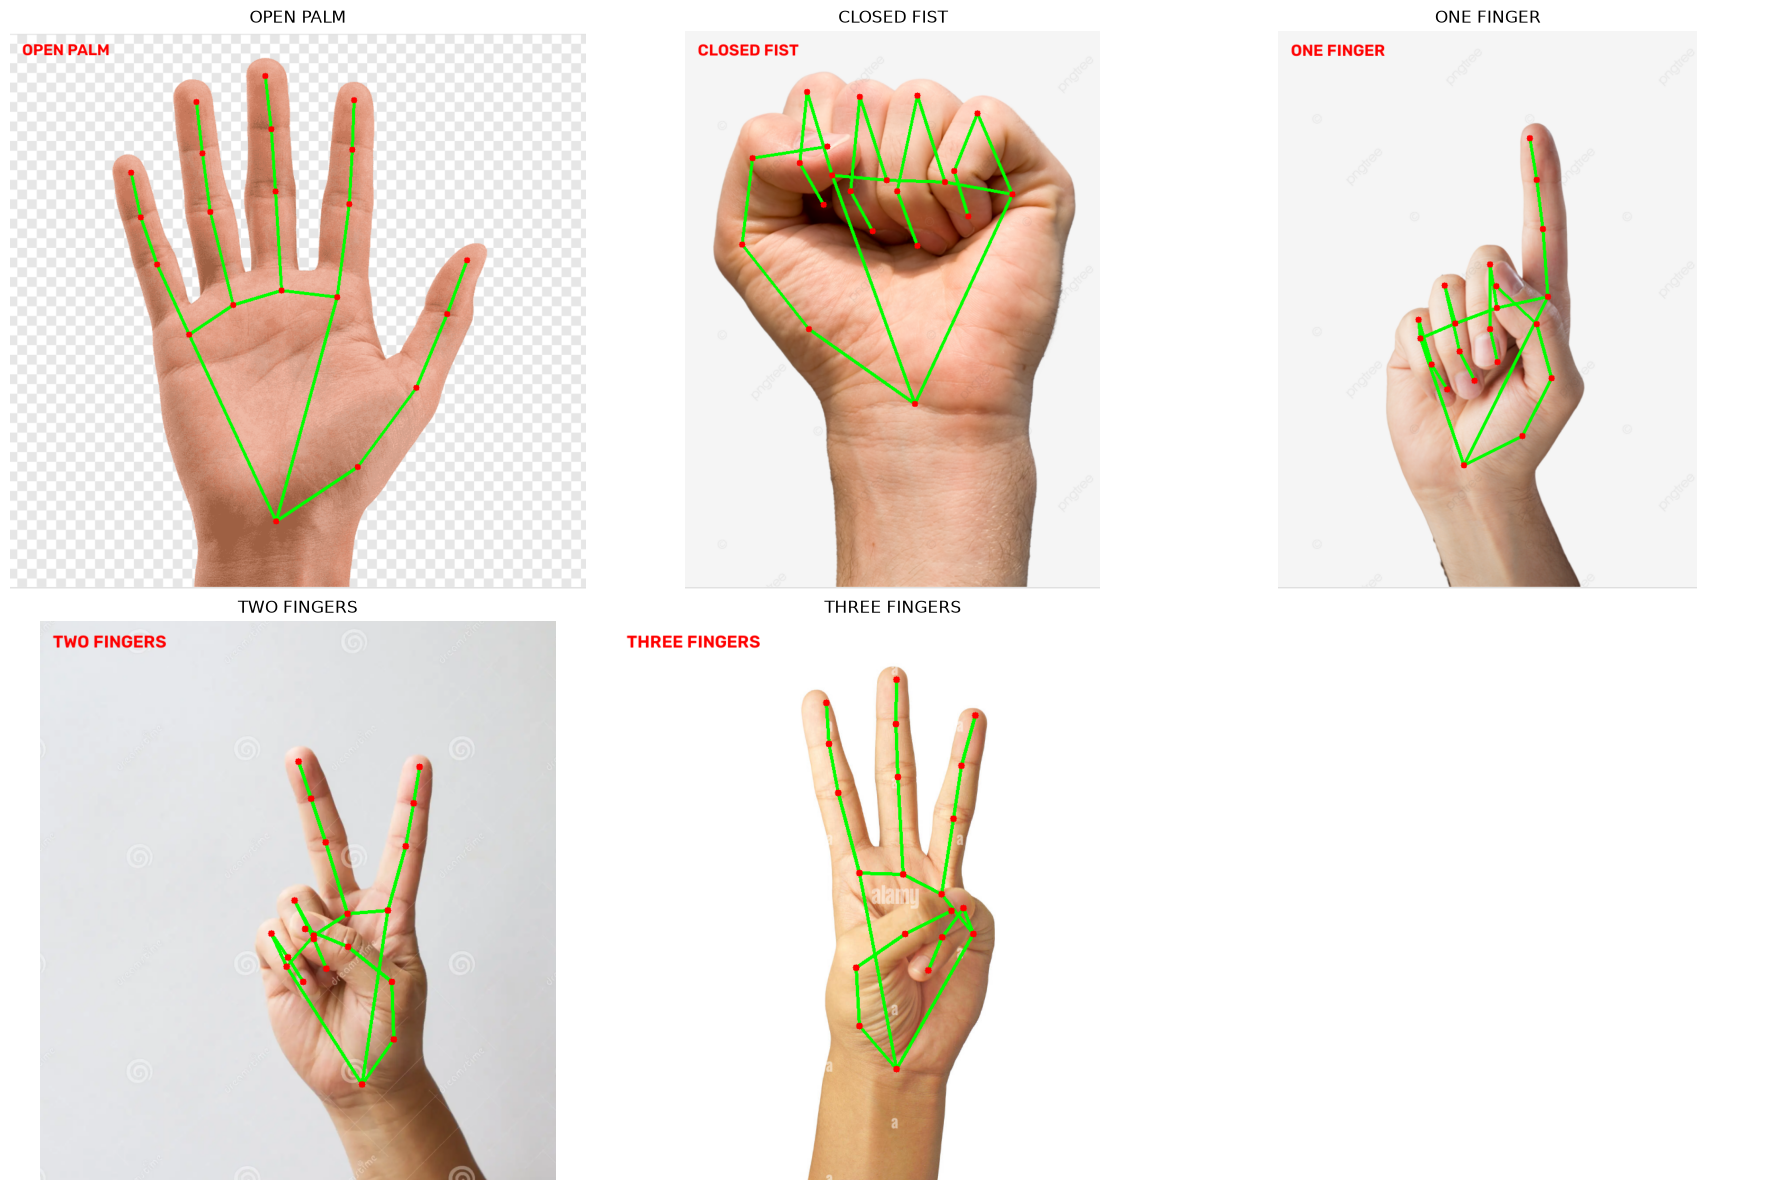

In [37]:
# Image names
image_files = [
    "hand.jpg",
    "closed_fist.jpg",
    "one_finger.jpg",
    "two_finger.jpg",
    "three_finger.jpg"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, filename in enumerate(image_files):

    image = cv2.imread(filename)

    if image is None:
        axes[i].set_title(f"{filename} not found")
        axes[i].axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width, _ = image.shape

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image
    )

    result = detector.detect(mp_image)

    output = image.copy()

    if result.hand_landmarks:

        hand = result.hand_landmarks[0]

        points = []

        for landmark in hand:
            x = int(landmark.x * width)
            y = int(landmark.y * height)
            points.append((x, y))

        # Draw connections
        for start, end in HAND_CONNECTIONS:
            cv2.line(
                output,
                points[start],
                points[end],
                (0, 255, 0),
                3
            )

        # Draw landmarks
        for point in points:
            cv2.circle(
                output,
                point,
                5,
                (255, 0, 0),
                -1
            )

        # Recognize gesture
        gesture = recognize_gesture_v2(hand)

        cv2.putText(
            output,
            gesture,
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (255, 0, 0),
            2
        )

    else:
        gesture = "NO HAND DETECTED"

    axes[i].imshow(output)
    axes[i].set_title(gesture)
    axes[i].axis("off")

axes[5].axis("off")

plt.tight_layout()
plt.show()


In [39]:
import cv2

def take_photo(filename="webcam.jpg"):
    cap = cv2.VideoCapture(0)
    print("اضغط SPACE للتصوير أو Q للخروج")
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        cv2.imshow("Camera", frame)
        key = cv2.waitKey(1) & 0xFF
        if key == 32:  # SPACE
            cv2.imwrite(filename, frame)
            break
        if key == ord("q"):
            filename = None
            break
    cap.release()
    cv2.destroyAllWindows()
    return filename

In [41]:
photo_path = take_photo()

if photo_path:
    print("Photo captured successfully!")
else:
    print("No photo taken.")

اضغط SPACE للتصوير أو Q للخروج
Photo captured successfully!


Detected Gesture: TWO FINGERS


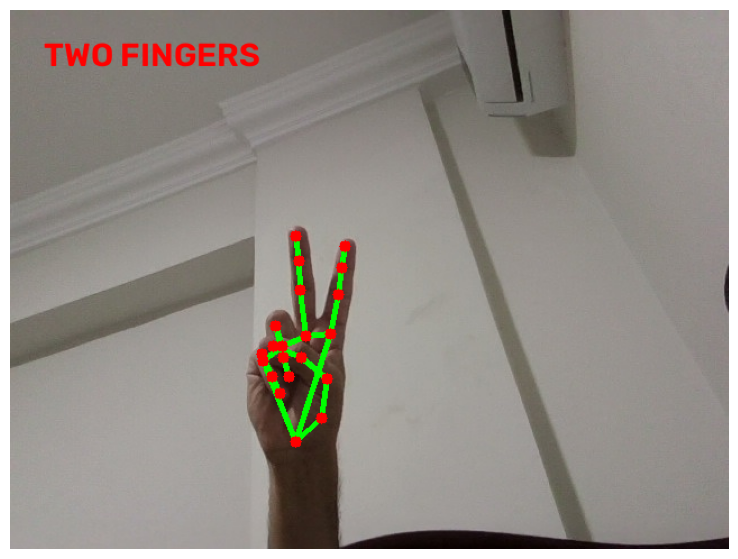

In [42]:
# Read webcam image
image = cv2.imread(photo_path)

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width, _ = image.shape

# Convert image to MediaPipe format
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image
)

# Detect hands
webcam_result = detector.detect(mp_image)

# Copy image
output = image.copy()

if webcam_result.hand_landmarks:

    for hand in webcam_result.hand_landmarks:

        # Draw connections and landmarks
        points = []

        for landmark in hand:

            x = int(landmark.x * width)
            y = int(landmark.y * height)

            points.append((x, y))

        for start, end in HAND_CONNECTIONS:

            cv2.line(
                output,
                points[start],
                points[end],
                (0, 255, 0),
                3
            )

        for point in points:

            cv2.circle(
                output,
                point,
                5,
                (255, 0, 0),
                -1
            )

        # Recognize gesture
        gesture = recognize_gesture_v2(hand)

        cv2.putText(
            output,
            gesture,
            (30, 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 0, 0),
            3
        )

        print("Detected Gesture:", gesture)

else:
    print("No hand detected!")

# Display result
plt.figure(figsize=(10, 7))
plt.imshow(output)
plt.axis("off")
plt.show()

In [48]:
import cv2
import time

def capture_photo(filename="webcam.jpg"):
    cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

    if not cap.isOpened():
        print("الكاميرا مفتحتش")
        return None

    # عدّ تنازلي عشان تجهّز إيدك
    for i in range(5, 0, -1):
        print(f"جهّز إيدك... {i}")
        time.sleep(1)

    # نقرا كذا frame عشان الكاميرا تظبط الإضاءة، ونحتفظ بآخر واحد
    frame = None
    for _ in range(15):
        ok, f = cap.read()
        if ok:
            frame = f

    cap.release()

    if frame is None:
        print("معرفتش أقرا صورة من الكاميرا")
        return None

    cv2.imwrite(filename, frame)
    print("تم التصوير وحفظ الصورة:", filename)
    return filename

photo_path = capture_photo()
print("photo_path =", photo_path)

جهّز إيدك... 5
جهّز إيدك... 4
جهّز إيدك... 3
جهّز إيدك... 2
جهّز إيدك... 1
تم التصوير وحفظ الصورة: webcam.jpg
photo_path = webcam.jpg


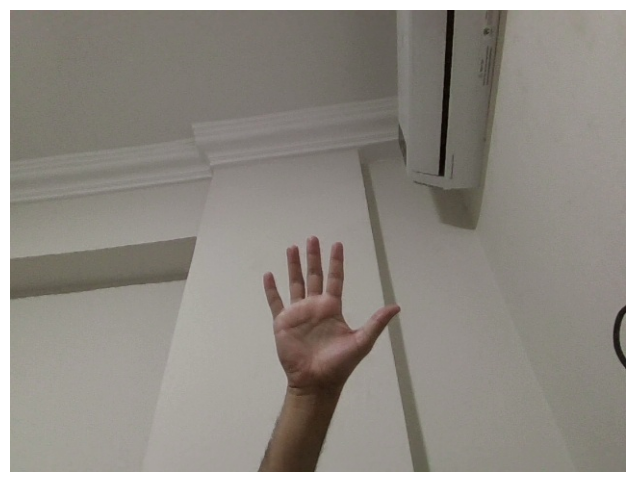

In [49]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

data = np.fromfile(photo_path, dtype=np.uint8)
image_bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

تم اكتشاف اليد، عدد النقط: 21


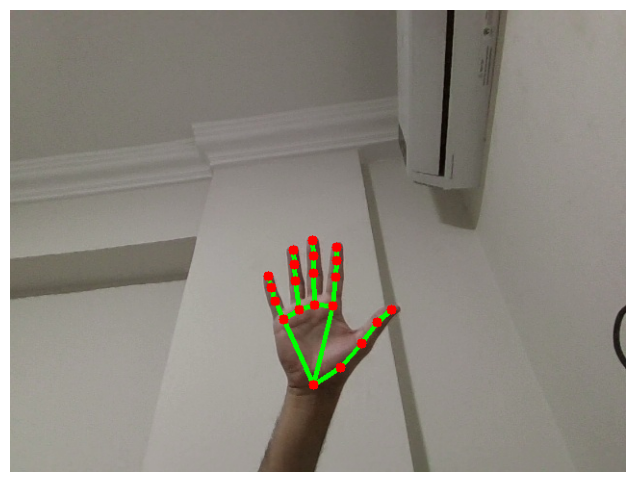

In [50]:
import os
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

# 1) تحميل ملف الموديل لو مش موجود
MODEL_URL = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
MODEL_PATH = "hand_landmarker.task"

if not os.path.exists(MODEL_PATH):
    print("بحمّل الموديل...")
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
    print("تم التحميل")

# 2) إعداد الـ detector (بنقرا الملف كبايتات عشان الحروف العربي في المسار متعملش مشكلة)
with open(MODEL_PATH, "rb") as f:
    model_bytes = f.read()

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_buffer=model_bytes),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
)
detector = vision.HandLandmarker.create_from_options(options)

# 3) الخطوط اللي بتوصل النقط ببعض
HAND_CONNECTIONS = [
    (0,1),(1,2),(2,3),(3,4),
    (0,5),(5,6),(6,7),(7,8),
    (5,9),(9,10),(10,11),(11,12),
    (9,13),(13,14),(14,15),(15,16),
    (13,17),(17,18),(18,19),(19,20),(0,17)
]

# 4) قراءة الصورة واكتشاف اليد
data = np.fromfile(photo_path, dtype=np.uint8)
image_bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width, _ = image.shape

mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image)
result = detector.detect(mp_image)

# 5) الرسم
output = image.copy()

if result.hand_landmarks:
    hand = result.hand_landmarks[0]
    points = [(int(p.x * width), int(p.y * height)) for p in hand]

    for start, end in HAND_CONNECTIONS:
        cv2.line(output, points[start], points[end], (0, 255, 0), 3)
    for pt in points:
        cv2.circle(output, pt, 5, (255, 0, 0), -1)

    print("تم اكتشاف اليد، عدد النقط:", len(hand))
else:
    print("مفيش إيد اتكتشفت")

plt.figure(figsize=(8, 6))
plt.imshow(output)
plt.axis("off")
plt.show()

الأصابع (سبابة، وسطى، بنصر، خنصر): [1, 1, 1, 1]
الإبهام مفرود؟ True
الإيماءة: OPEN PALM


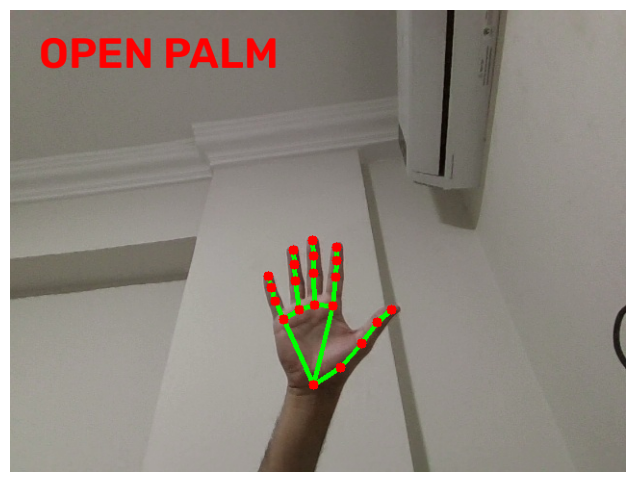

In [51]:
import math

# ===== الدوال =====
def calculate_distance(a, b):
    return math.hypot(a.x - b.x, a.y - b.y)

def count_fingers(lm):
    wrist = lm[0]
    tips = [8, 12, 16, 20]   # أطراف السبابة والوسطى والبنصر والخنصر
    pips = [6, 10, 14, 18]   # المفصل الأوسط لكل إصبع
    return [
        1 if calculate_distance(lm[t], wrist) >
             calculate_distance(lm[p], wrist) * 1.1 else 0
        for t, p in zip(tips, pips)
    ]

def detect_thumb(lm):
    palm_width = calculate_distance(lm[5], lm[17])
    away_from_pinky = (calculate_distance(lm[4], lm[17]) >
                       calculate_distance(lm[3], lm[17]) * 1.05)
    away_from_index = calculate_distance(lm[4], lm[5]) > palm_width * 0.7
    return away_from_pinky and away_from_index

def recognize_gesture_v2(lm):
    fingers = count_fingers(lm)
    thumb_open = detect_thumb(lm)
    total = sum(fingers)
    palm_width = calculate_distance(lm[5], lm[17])
    thumb_tip, wrist = lm[4], lm[0]

    # OK sign
    if (calculate_distance(lm[4], lm[8]) < palm_width * 0.25
            and fingers[1] == 1 and fingers[2] == 1 and fingers[3] == 1):
        return "OK SIGN"

    # Thumbs up / down
    if thumb_open and total == 0:
        if thumb_tip.y < wrist.y - palm_width * 0.5:
            return "THUMBS UP"
        if thumb_tip.y > wrist.y + palm_width * 0.5:
            return "THUMBS DOWN"

    if total == 4: return "OPEN PALM"
    if total == 0: return "CLOSED FIST"
    if total == 1: return "ONE FINGER"
    if total == 2: return "TWO FINGERS"
    if total == 3: return "THREE FINGERS"
    return "UNKNOWN"

# ===== التطبيق على صورتك =====
if result.hand_landmarks:
    hand = result.hand_landmarks[0]

    print("الأصابع (سبابة، وسطى، بنصر، خنصر):", count_fingers(hand))
    print("الإبهام مفرود؟", detect_thumb(hand))

    gesture = recognize_gesture_v2(hand)
    print("الإيماءة:", gesture)

    cv2.putText(output, gesture, (30, 60),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 0, 0), 4)

    plt.figure(figsize=(8, 6))
    plt.imshow(output)
    plt.axis("off")
    plt.show()
else:
    print("مفيش إيد اتكتشفت")